<a href="https://colab.research.google.com/github/alyacipta/My-AI-Labs/blob/main/Computer-Vision/OpenCV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **OpenCV**
library yang sangat kepake didunia Computer Vision. Sangat berguna dan sering banget dipakai untuk proses **data augmentation** dalam Computer Vision, terutama untuk memanipulasi gambar mentah sebelum dimasukkan ke model AI.

## **Input / Output**
1. Image
2. Video
3. Webcam

In [8]:
import os
import cv2
from google.colab.patches import cv2_imshow

In [5]:
image_path = '/content/bird.jpg'
img = cv2.imread(image_path)

In [6]:
if img is None:
    print(f"Error: Cannot save image because 'img' is None. Please check if '{image_path}' exists.")
else:
    os.makedirs(os.path.join('.', 'data'), exist_ok=True)
    cv2.imwrite(os.path.join('.', 'data', 'bird_out.jpg'), img)
    print("Image successfully saved to ./data/bird_out.jpg")

Image successfully saved to ./data/bird_out.jpg


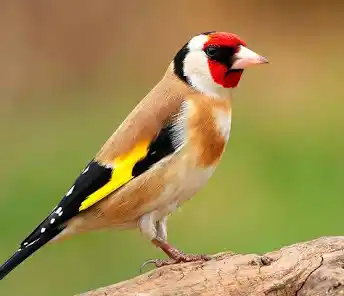

-1

In [7]:
# Use the Colab-specific replacement function to display the image inline
cv2_imshow(img)
cv2.waitKey(0)

In [ ]:
# read video
video_path = '/content/bird.mp4'
video = cv2.VideoCapture(video_path)

In [ ]:
# visualize video
ret = True
while ret:
    ret, frame = video.read()
    if ret:
        cv2_imshow(frame)
        cv2.waitKey(40)

video.release()
cv2.destroyAllWindows()

NameError: name 'video' is not defined

In [ ]:
# read webcam
webcam = cv2.VideoCapture(2)


# visualize webcam
ret = True
while ret:
    ret, frame = webcam.read()
    if ret:
        cv2_imshow(frame)
        if cv2.waitKey(40) & 0xFF == ord('q'):
          break

webcam.release()
cv2.destroyAllWindows()

<IPython.core.display.Javascript object>

Saved to photo.jpg


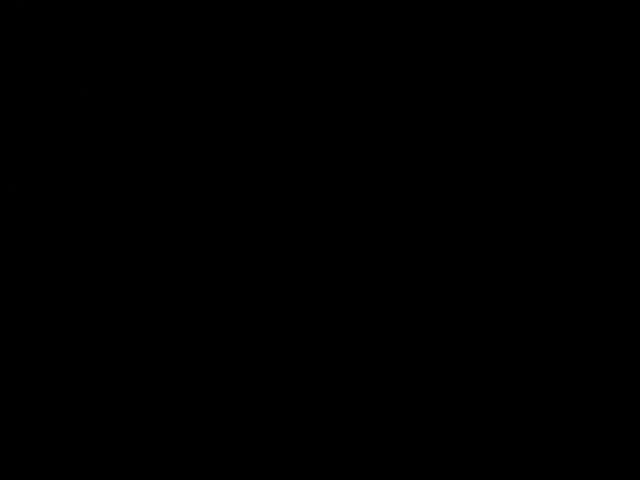

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import numpy as np
import cv2

def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

try:
  filename = take_photo()
  print('Saved to {}'.format(filename))

  # Show the image which was just taken.
  img_webcam = cv2.imread(filename)
  from google.colab.patches import cv2_imshow
  cv2_imshow(img_webcam)
except Exception as err:
  # Errors will be thrown if the user does not have a webcam or denies camera permissions
  print(str(err))

**notes:**
tampilkan webcam di g.collab perlu javascript supaya dia beneran bisa menampilkan pop up webcam nya.
Bedanya, kalau pakai di vscode langsung di local komputer, tanpa java script bisa langsung menampilkan

## **Leasson 3: Basic Operations**
1. Resizing
2. Crop

basic but important

Original Dimensions :  (296, 344, 3)
Resized Dimensions :  (640, 640, 3)


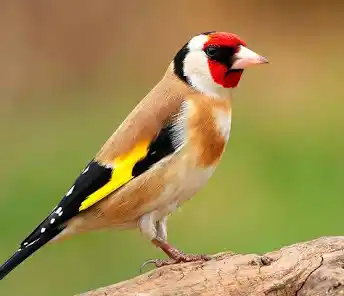

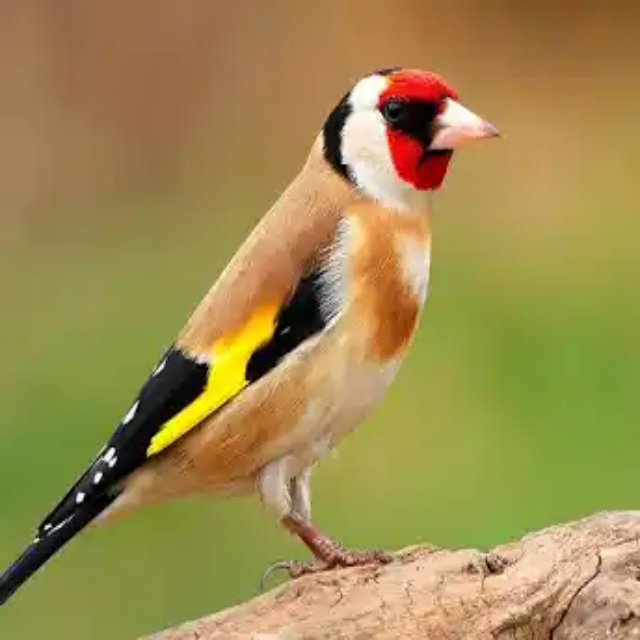

In [ ]:
# resizing
from google.colab.patches import cv2_imshow

img = cv2.imread(image_path)
resized_img = cv2.resize(img, (640, 640))

print('Original Dimensions : ',img.shape)
print('Resized Dimensions : ',resized_img.shape)

# Menggunakan cv2_imshow dari patch Colab
cv2_imshow(img)
cv2_imshow(resized_img)
cv2.waitKey(0)
cv2.destroyAllWindows()

Original Dimensions :  (296, 344, 3)
Cropped Dimensions :  (96, 24, 3)


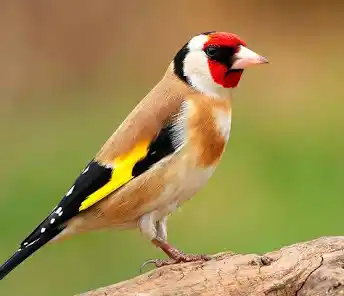

In [ ]:
# crop
from google.colab.patches import cv2_imshow

img = cv2.imread(image_path)
cropped_img = img[200:740, 320:940]

print('Original Dimensions : ',img.shape)
print('Cropped Dimensions : ',cropped_img.shape)

# cv2_imshow hanya menerima variabel gambar saja
cv2_imshow(img)
cv2_imshow(cropped_img)
cv2.waitKey(0)
cv2.destroyAllWindows()

## **Lesson 4: Colorspaces**
tentang penempatan warna nya, kita bisa switch dari BGR ke RGB, atau BGR ke GRAY, ato BGR ke HSV (Hue, Saturation, Value).

intinya ini berkaitan dengan matkul KodKom (disemester 5), yg mengenai data image

masih banyak banget sebenanya color spaces yg bisa di eksplore, saking banyaknya bisa jadi ratusan line codingan ini. ini hanya yg essential dan populer saja yg di pake untuk latihan ini. sisanya pas mau bikin project cari aja di internet "OpenCV Color Spaces"

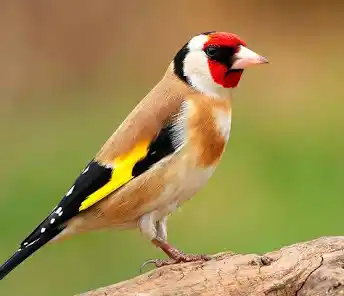

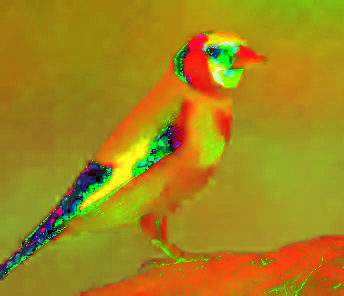

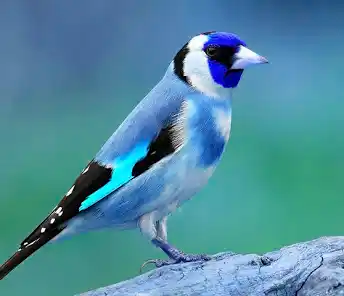

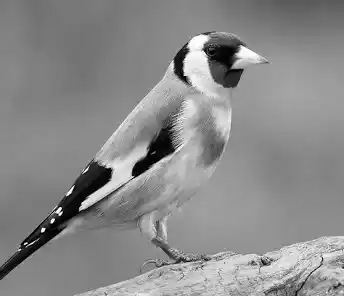

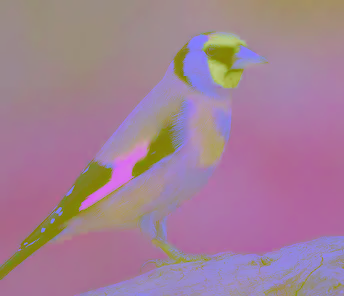

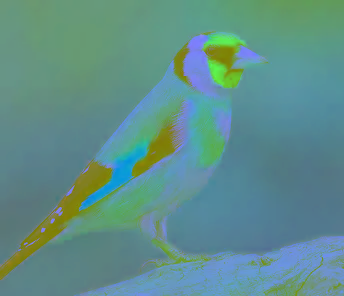

-1

In [16]:
img = cv2.imread(image_path)
img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
#img_gbr = cv2.cvtColor(img, cv2.COLOR_BGR2GBR) // error kalau jalan kan ini
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img_lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
img_YCrCb = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)

cv2_imshow(img)
cv2_imshow(img_hsv)
cv2_imshow(img_rgb)
#cv2_imshow(img_gbr)
cv2_imshow(img_gray)
cv2_imshow(img_lab)
cv2_imshow(img_YCrCb)
cv2.waitKey(0)

aku habis coba

img_gbr = cv2.cvtColor(img, cv2.COLOR_BGR2GBR)

cv2_imshow(img_gbr)

ku pikir itu hanya urutan huruf aja, ternyata GBR tuh error, katanya "module 'cv2' has no attribute 'COLOR_BGR2GBR'"

# Leasson 5: Blurring
function Blurring di OpenCV:


*   blur()
*   GausslanBlur()
*   medianBlur()
*   billateralFilter() -> paling canggih dan keknya ini yg dipake editor foto untuk muluskan muka orang deh

sama2 membuat blur cuman cara matematika di balik layarnya saja yg berbeda.

Teknik blurring ini g hanya berguna untuk foto yg mau kita blur, tapi juga berguna untuk gambar yg penuh noise sehingga noise nya jadi lebih mulus



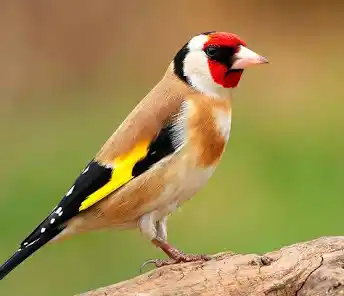

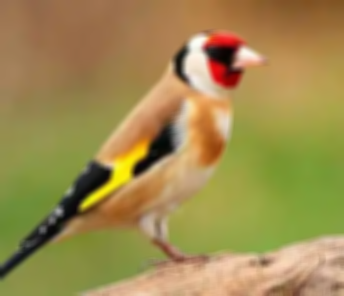

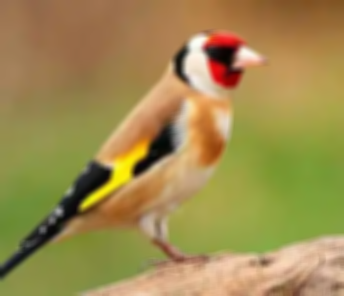

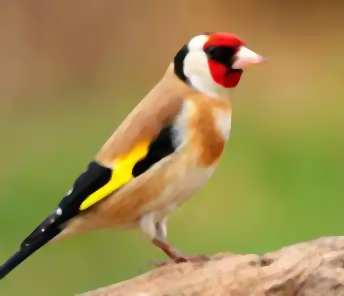

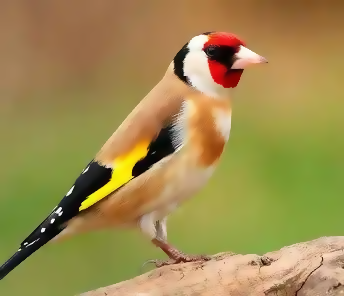

-1

In [24]:
img = cv2.imread(image_path)
k_size = (7, 7)  # Fixed: GaussianBlur requires odd kernel dimensions
blur_img = cv2.blur(img, k_size)
gauss_img = cv2.GaussianBlur(img, k_size, 10)
median_img = cv2.medianBlur(img, 5)
bilat_img = cv2.bilateralFilter(img, 9, 75, 75)

cv2_imshow(img)
cv2_imshow(blur_img)
cv2_imshow(gauss_img)
cv2_imshow(median_img)
cv2_imshow(bilat_img)
cv2.waitKey(0)

# **Leasson 6: Threshold**
ada 2 function untuk threshol ini:
1. cv.threshold
2. cv.adaptiveThreshold

atur2 saja valuenya (yg angka2 itu) sehingga dapat keluaran yg pas dan bersih

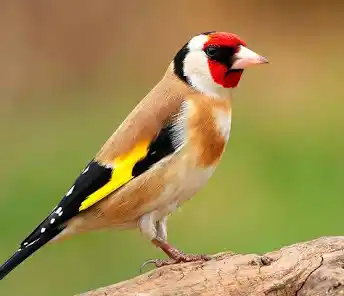

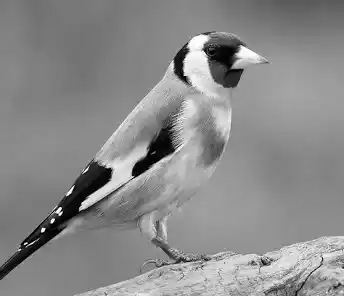

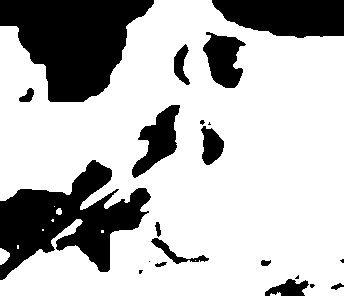

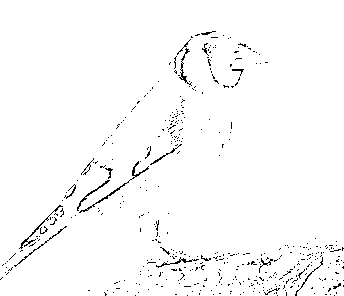

-1

In [32]:
img = cv2.imread(image_path)

img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# simple threshold
ret, thresh_img = cv2.threshold(img_gray, 127, 255, cv2.THRESH_BINARY)

# klo mau coba hilangkan noise di backgroudnya, jadi bener2 bersih
thresh_img = cv2.blur(thresh_img, (5, 5))
ret, thresh_img = cv2.threshold(thresh_img, 127, 255, cv2.THRESH_BINARY)

# adaptive threshold
thresh_img_adapt = cv2.adaptiveThreshold(img_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 30)

cv2_imshow(img)
cv2_imshow(img_gray)
cv2_imshow(thresh_img)
cv2_imshow(thresh_img_adapt) # wow, kayak menggambar
cv2.waitKey(0)

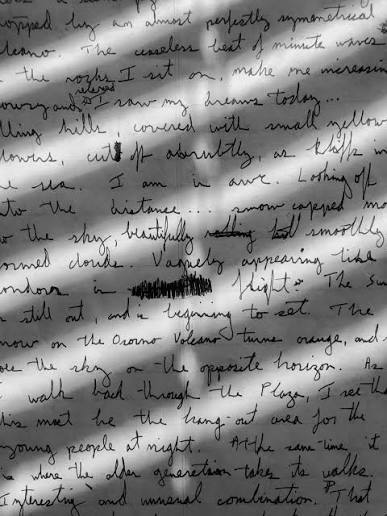

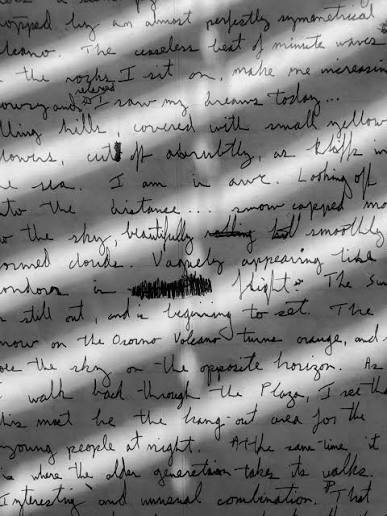

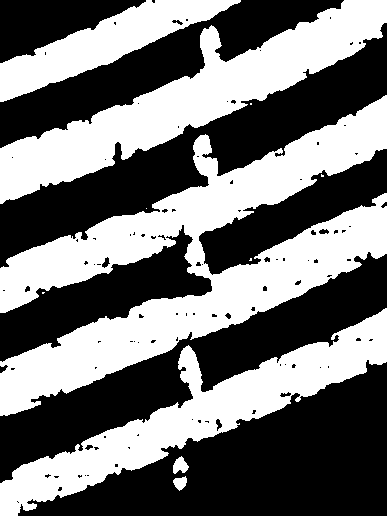

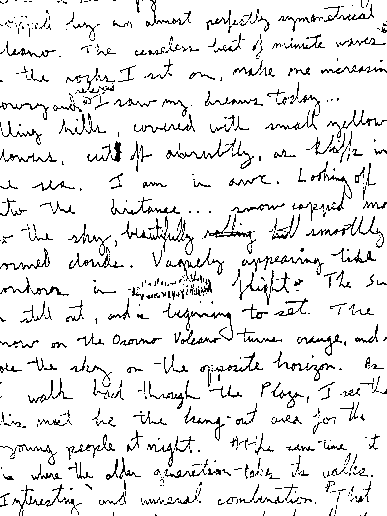

-1

In [30]:
# masih threshold tapi pake gambar handwritten
img = cv2.imread('/content/handwritten.jpg')

img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# simple threshold
ret, thresh_img = cv2.threshold(img_gray, 127, 255, cv2.THRESH_BINARY)

thresh_img = cv2.blur(thresh_img, (5, 5))
ret, thresh_img = cv2.threshold(thresh_img, 127, 255, cv2.THRESH_BINARY)

# adaptive threshold
thresh_img_adapt = cv2.adaptiveThreshold(img_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 21, 30)

cv2_imshow(img)
cv2_imshow(img_gray)
cv2_imshow(thresh_img)
cv2_imshow(thresh_img_adapt)
cv2.waitKey(0)

woh, sepertinya aku jadi kebayang gimana proses fitur camscanner yang dari handwritten ke background putih saja ke text.

yang dimana proses threshold ini berfungsi untuk hilangkan noise nya, lalu setelah bener2 bersih dan kebaca modelnya jadi bisa ubah ke text. sepertinya, cmiiw

# **Leasson 7: Edge Detection**

# **Leasson 8: Drawing**

# **Leasson 9: Contours**

# **Leasson 10: Human Vision**